In [75]:
# ДЗ 4
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

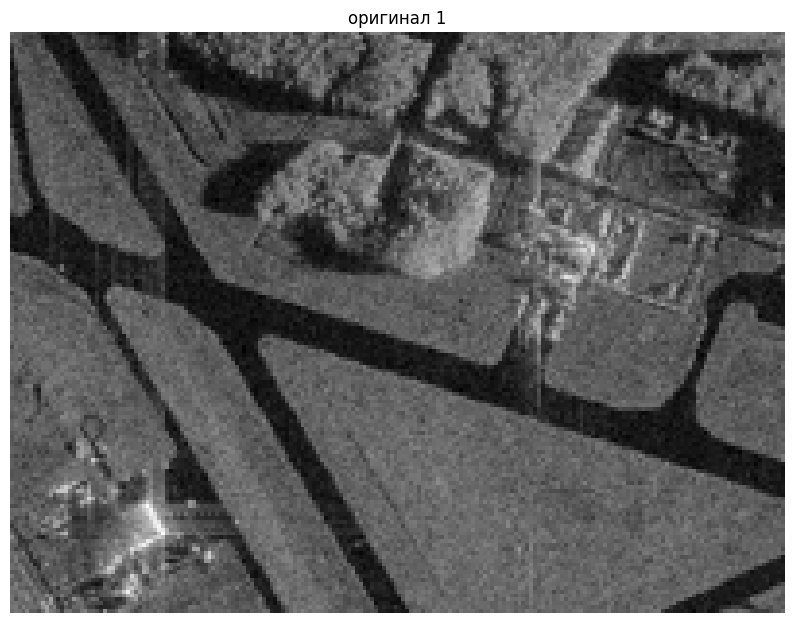

In [68]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_gray = cv2.resize(image_gray, (0, 0), fx=0.5, fy=0.5)

plt.figure(figsize=(10, 8))
plt.imshow(image_gray, cmap='gray')
plt.title("оригинал 1")
plt.axis('off')
plt.show()

In [69]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    if abs(av_val - img[point]) <= T:
        return True
    return False

def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i-r:i+r, j-r:j+r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
    return mask * 255

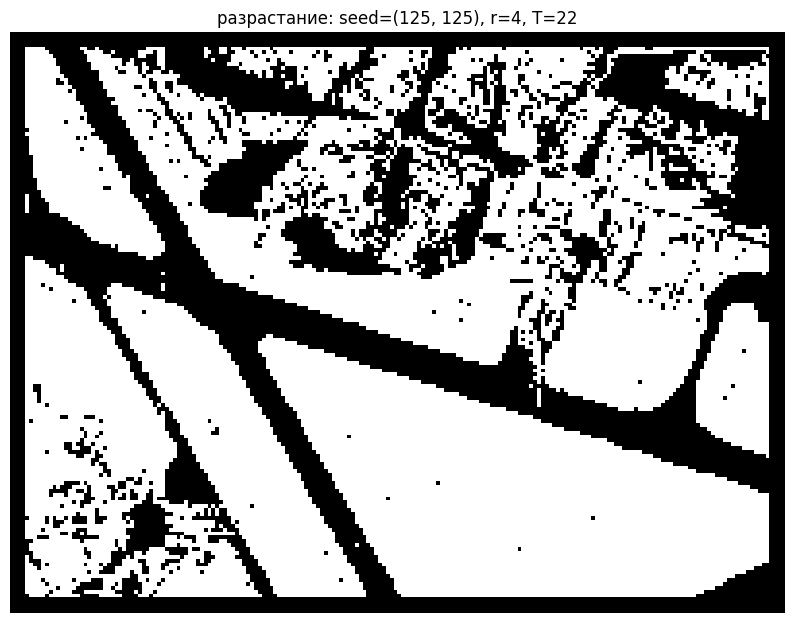

площадь маски: 18685 пикселей
общая площадь: 30000


In [70]:
seed_point = (125, 125)
r = 4
T = 22

mask_avg = region_growing(image_gray, seed_point, homo_average, r, T)

plt.figure(figsize=(10, 8))
plt.imshow(mask_avg, cmap='gray')
plt.title(f"разрастание: seed={seed_point}, r={r}, T={T}")
plt.axis('off')
plt.show()

print("площадь маски:", np.count_nonzero(mask_avg), "пикселей")
print("общая площадь:", image_gray.shape[0] * image_gray.shape[1])

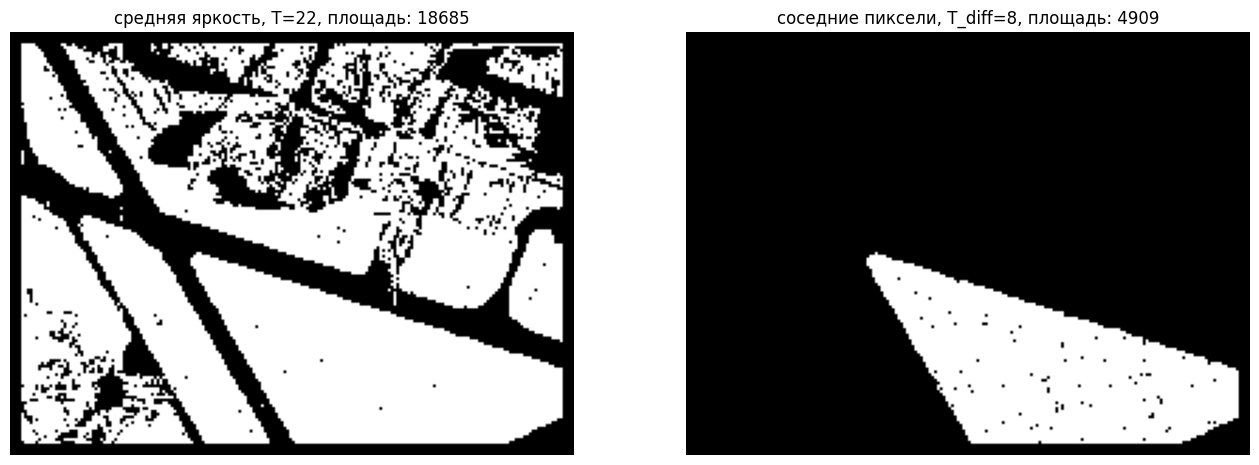

среднее: 18685 пикселей
соседи: 4909 пикселей


In [71]:
def homo_neighbor(img, mask, point, T_diff):
    i, j = point
    current = int(img[point])

    local = img[i-1:i+2, j-1:j+2]
    local_mask = mask[i-1:i+2, j-1:j+2] > 0
    neighbors = local[local_mask]
    if neighbors.size == 0:
        return False
    return np.any(np.abs(neighbors.astype(np.int16) - current) <= T_diff)

T_diff = 8
mask_neighbor = region_growing(image_gray, seed_point, homo_neighbor, r, T_diff)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(mask_avg, cmap='gray')
plt.title(f"средняя яркость, T={T}, площадь: {np.count_nonzero(mask_avg)}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_neighbor, cmap='gray')
plt.title(f"соседние пиксели, T_diff={T_diff}, площадь: {np.count_nonzero(mask_neighbor)}")
plt.axis('off')
plt.show()

print("среднее:", np.count_nonzero(mask_avg), "пикселей")
print("соседи:", np.count_nonzero(mask_neighbor), "пикселей")

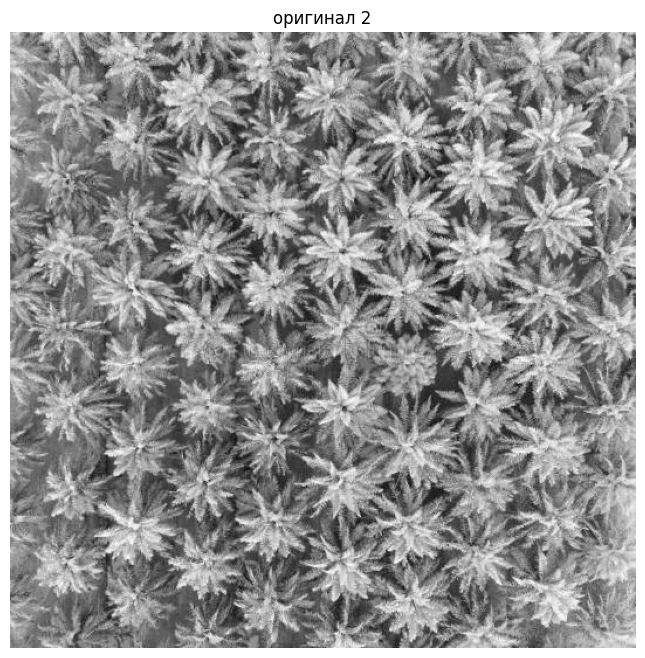

In [72]:
palm = cv2.imread('palm_1.JPG')
palm_rgb = cv2.cvtColor(palm, cv2.COLOR_BGR2RGB)
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 8))
plt.imshow(palm_gray, cmap='gray')
plt.title("оригинал 2")
plt.axis('off')
plt.show()

оцу подобрал порог: 160.0


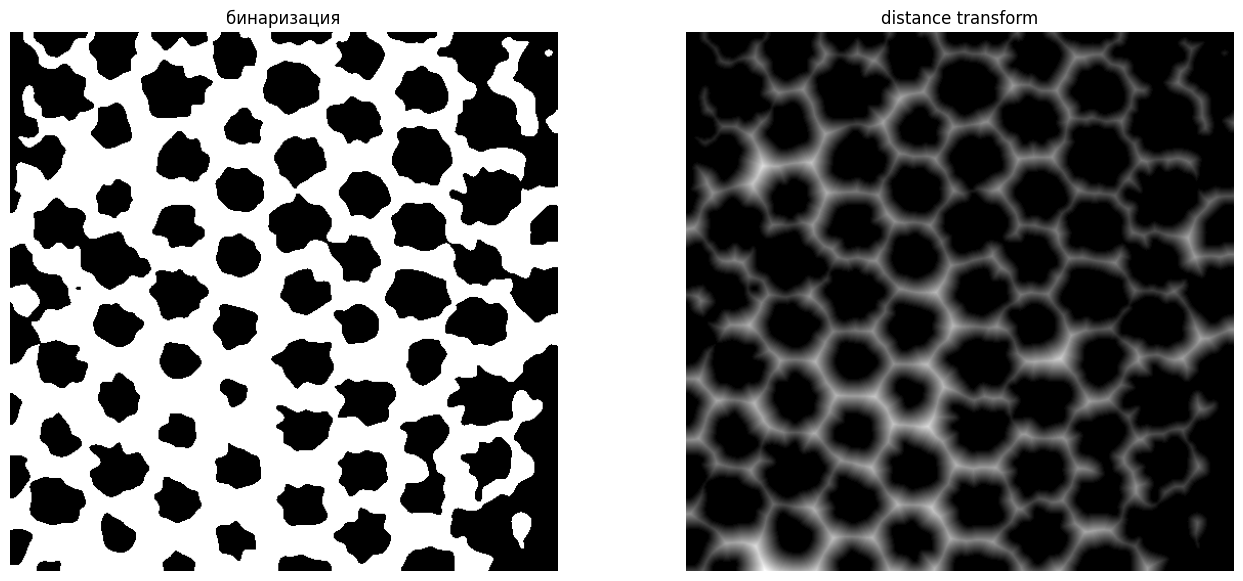

In [78]:
blurred = cv2.GaussianBlur(palm_gray, (31, 31), 0)

ret, thresh = cv2.threshold(blurred, 0, 255,
                            cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("оцу подобрал порог:", ret)

dist_transform = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(thresh, cmap='gray')
plt.title("бинаризация")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(dist_transform, cmap='gray')
plt.title("distance transform")
plt.axis('off')
plt.show()

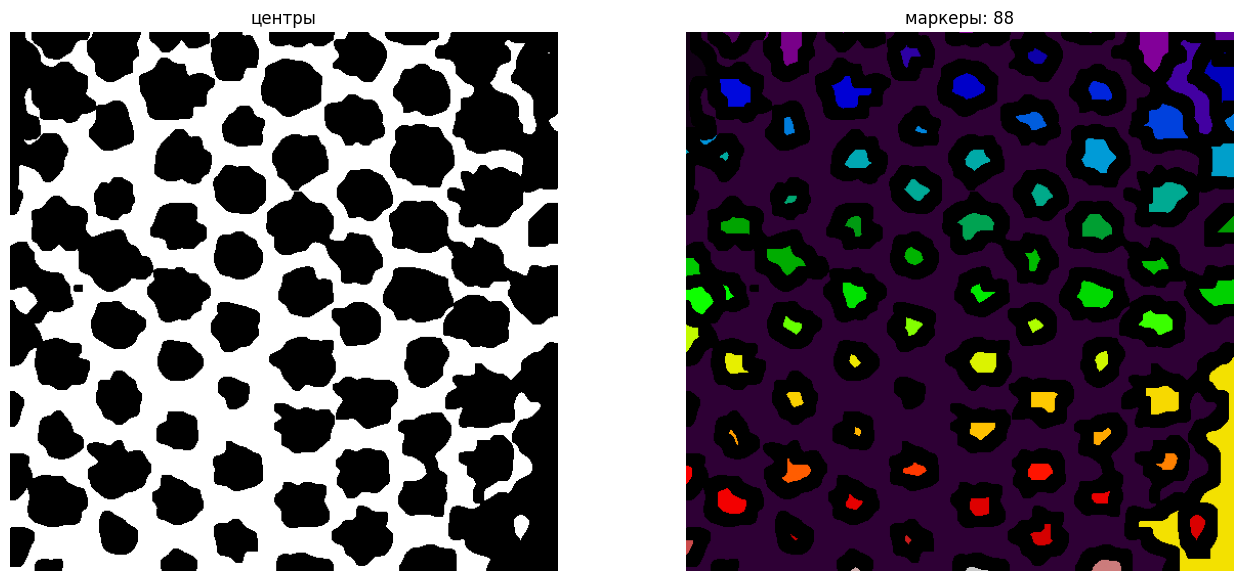

In [74]:
local_maxima = ndimage.maximum_filter(dist_transform, size=20, mode='constant')

ret, sure_fg = cv2.threshold(dist_transform, 0.1 * dist_transform.max(), 255,
                             cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

ret, markers = cv2.connectedComponents(sure_fg)
markers[dist_transform == local_maxima] = 1
markers = ndimage.label(markers)[0]

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(sure_fg, cmap='gray')
plt.title("центры")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(markers, cmap='nipy_spectral')
plt.title(f"маркеры: {len(np.unique(markers)) - 1}")
plt.axis('off')
plt.show()

найдено деревьев: 85


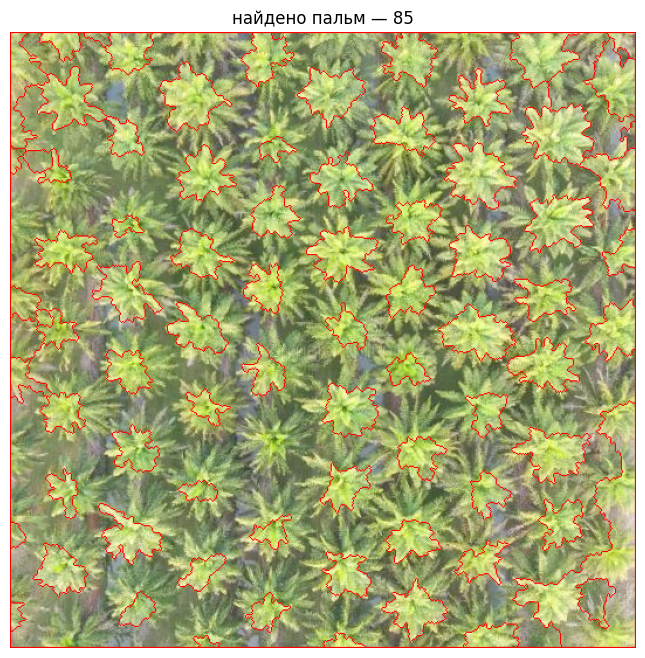

In [75]:
markers = cv2.watershed(palm, markers.astype(np.int32))

num_trees = len(np.unique(markers)) - 1
print("найдено деревьев:", num_trees)


segmented_image = palm_rgb.copy()
segmented_image[markers == -1] = [255, 0, 0]

plt.figure(figsize=(10, 8))
plt.imshow(segmented_image)
plt.title(f"найдено пальм — {num_trees}")
plt.axis('off')
plt.show()